In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical

In [3]:
# Load Data 
faces = fetch_olivetti_faces(shuffle=False)
X = faces.images      
y = faces.target      
print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of people:", len(np.unique(y)))

Images: (400, 64, 64)
Labels: (400,)
Number of people: 40


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, stratify=y, random_state=42)

y_train_cat = to_categorical(y_train, 40)
y_test_cat = to_categorical(y_test, 40)

X_train = X_train.reshape(-1, 64, 64, 1)
X_test = X_test.reshape(-1, 64, 64, 1)
idx = 0

In [12]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model

input_tensor = Input(shape=(64, 64, 1))
conv = Conv2D(16, (3, 3), strides=1, padding="same", activation="relu")(input_tensor)
pool = MaxPooling2D(pool_size=(2, 2), strides=2)(conv)
flat = Flatten()(pool)
output = Dense(40, activation="softmax")(flat)

model1 = Model(inputs=input_tensor, outputs=output)
model1.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model1.fit(X_train, y_train_cat, epochs=20, batch_size=10, verbose=0)

loss, accuracy = model1.evaluate(X_test, y_test_cat, verbose=0)

In [13]:
# Step 11: Model 2's Architecture
# Change model 1 so that it has a window size of 9.
input_tensor2 = Input(shape=(64, 64, 1))

# Convolution Neural Network Model
conv2 = Conv2D(filters=16, kernel_size=(9, 9), strides=1,padding="same", activation="relu", name="conv_layer_2")(input_tensor2)
pool2 = MaxPooling2D(pool_size=(2, 2), strides=2,padding="valid", name="pool_layer_2")(conv2)
flat2 = Flatten(name="flatten_2")(pool2)
output2 = Dense(40, activation="softmax", name="output_layer_2")(flat2)

model2 = Model(inputs=input_tensor2, outputs=output2)

# Compiling model2 (same settings as model1)
model2.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])
model2.summary()

# Train with the same settings: 20 epochs, batch size 10
history2 = model2.fit(X_train, y_train_cat,epochs=20, batch_size=10, verbose=1)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_layer_2 (Conv2D)                │ (None, 64, 64, 16)          │           1,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_layer_2 (MaxPooling2D)          │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer_2 (Dense)               │ (None, 40)                  │         655,400 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 656,712 (2.51 MB)

 Trainable params: 656,712 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.0100 - loss: 3.8153
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0900 - loss: 3.6871
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.0700 - loss: 3.6765
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.1450 - loss: 3.5947
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.1450 - loss: 3.3460
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5400 - loss: 2.8771
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6800 - loss: 2.2548
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8400 - loss: 1.4953
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9100 - loss: 0.9856
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9450 - loss: 0.6136
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9850 - loss: 0.4193
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy:

In [14]:
# Step 12: Model 2's loss and accuracy
loss2, accuracy2 = model2.evaluate(X_test, y_test_cat, verbose=0)
print(f"Model 2 test loss: {loss2:.4f}")
print(f"Model 2 test accuracy: {accuracy2:.4f}")

# Comparison with Model 1
print("\nModel comparison (test set)")
print(f"Model 1 (3x3 window): loss = {loss:.4f}, accuracy = {accuracy:.4f}")
print(f"Model 2 (9x9 window): loss = {loss2:.4f}, accuracy = {accuracy2:.4f}")

Model 2 test loss: 0.5305
Model 2 test accuracy: 0.8700

Model comparison (test set)
Model 1 (3x3 window): loss = 0.3682, accuracy = 0.9150
Model 2 (9x9 window): loss = 0.5305, accuracy = 0.8700


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
Conv feature maps: (1, 64, 64, 16)
Pool feature maps: (1, 32, 32, 16)


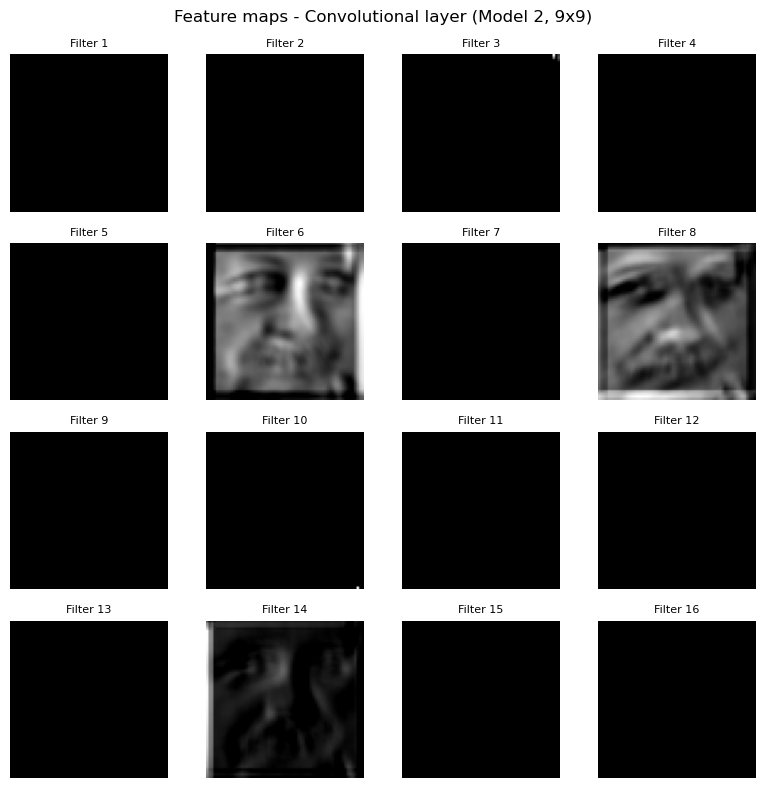

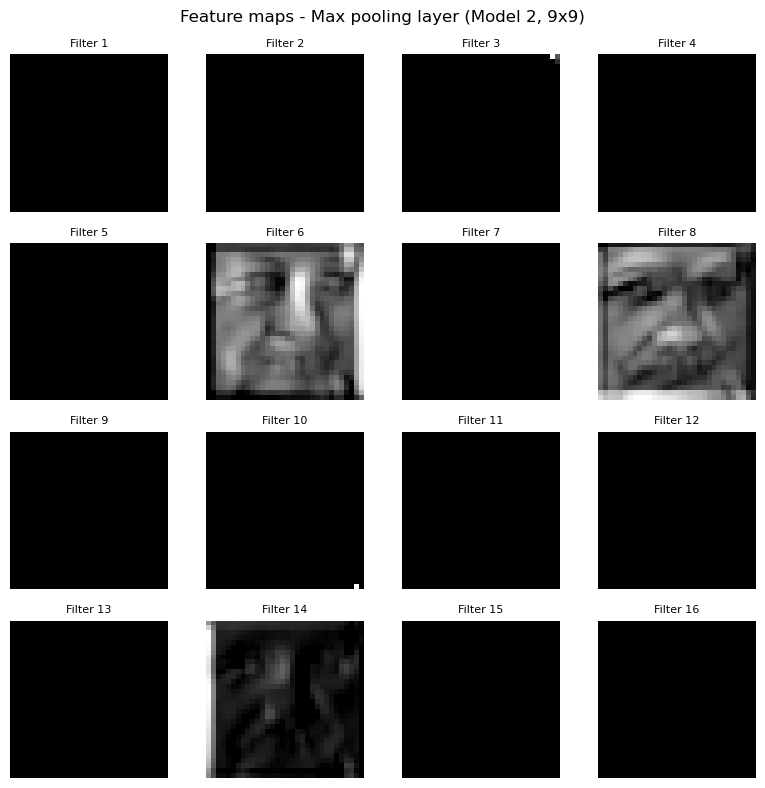

In [17]:
# Step 13: Feature maps (same image as Steps 9 and 10)
feature_model2 = Model(inputs=model2.input, outputs=[conv2, pool2])
img = X_test[idx:idx + 1]                         # same idx as Part 2
conv_maps2, pool_maps2 = feature_model2.predict(img)
print("Conv feature maps:", conv_maps2.shape)     # (1, 64, 64, 16)
print("Pool feature maps:", pool_maps2.shape)     # (1, 32, 32, 16)

# For loop: plot all 16 maps for each layer
for name, maps in [("Convolutional layer (Model 2, 9x9)", conv_maps2),
                   ("Max pooling layer (Model 2, 9x9)", pool_maps2)]:
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(maps[0, :, :, i], cmap="gray")
        ax.set_title(f"Filter {i + 1}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Feature maps - {name}")
    plt.tight_layout()
    plt.show()